# start2impact University | Progetto Advanced Analytics

Ti diamo il benvenuto nel notebook del progetto del Corso Advanced Analytics!

Prima di tutto bisogna importare una serie di librerie core, che saranno quelle principali per rispondere alle domande del progetto:

In [1]:
import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt

Per usare il tuo Google Drive con Colab, bisogna montarlo tramite il seguente comando. Dovrebbe chiederti l'accesso tramite il tuo account Google, concediglielo e seleziona tutte le spunte disponibili.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Dopodiché puoi partire con l'importazione del dataset **supermarket sales**, il primo che ti servirà: dovresti averlo già uploadato nel tuo Drive, inserisci la location dove lo hai salvato andando a sostituire il placeholder *{PATH_AL_FILE_SUL_TUO_DRIVE}*, così da importarlo nell'ambiente di lavoro:

In [3]:
regression_raw_dataset = pd.read_csv('/content/drive/MyDrive/dataset/adv_analytics/supermarket_sales.csv', encoding='windows-1254')

# Esplorazione del dataset

**In questa breve sezione andrai a visualizzare il dataset in forma tabellare**, così da averne una rappresentazione più intuitiva e comprendere meglio con che tipologia di dato hai a che fare. Per semplicità si mostrano solo le prime 100 occorrenze.

In [4]:
regression_raw_dataset.head(100)

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,594-34-4444,A,Yangon,Normal,Male,Electronic accessories,97.16,1,4.8580,102.0180,3/8/2019,20:38,Ewallet,97.16,4.761905,4.8580,7.2
96,766-85-7061,B,Mandalay,Normal,Male,Health and beauty,87.87,10,43.9350,922.6350,3/29/2019,10:25,Ewallet,878.70,4.761905,43.9350,5.1
97,871-39-9221,C,Naypyitaw,Normal,Female,Electronic accessories,12.45,6,3.7350,78.4350,2/9/2019,13:11,Cash,74.70,4.761905,3.7350,4.1
98,865-92-6136,A,Yangon,Normal,Male,Food and beverages,52.75,3,7.9125,166.1625,3/23/2019,10:16,Ewallet,158.25,4.761905,7.9125,9.3


Vai quindi a vedere più nel dettaglio quali sono i metadati principali delle colonne del dataset:

In [5]:
regression_raw_dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1000 non-null   object 
 1   Branch                   1000 non-null   object 
 2   City                     1000 non-null   object 
 3   Customer type            1000 non-null   object 
 4   Gender                   1000 non-null   object 
 5   Product line             1000 non-null   object 
 6   Unit price               1000 non-null   float64
 7   Quantity                 1000 non-null   int64  
 8   Tax 5%                   1000 non-null   float64
 9   Total                    1000 non-null   float64
 10  Date                     1000 non-null   object 
 11  Time                     1000 non-null   object 
 12  Payment                  1000 non-null   object 
 13  cogs                     1000 non-null   float64
 14  gross margin percentage  

In [130]:
regression_raw_dataset.describe()

,Unit price,Quantity,Tax 5%,Total,cogs,gross margin percentage,gross income,Rating
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1.000000e+03,1000.000000,1000.00000
mean,55.672130,5.510000,15.379369,322.966749,307.58738,4.761905e+00,15.379369,6.97270
std,26.494628,2.923431,11.708825,245.885335,234.17651,6.131498e-14,11.708825,1.71858
min,10.080000,1.000000,0.508500,10.678500,10.17000,4.761905e+00,0.508500,4.00000
25%,32.875000,3.000000,5.924875,124.422375,118.49750,4.761905e+00,5.924875,5.50000
50%,55.230000,5.000000,12.088000,253.848000,241.76000,4.761905e+00,12.088000,7.00000
75%,77.935000,8.000000,22.445250,471.350250,448.90500,4.761905e+00,22.445250,8.50000
max,99.960000,10.000000,49.650000,1042.650000,993.00000,4.761905e+00,49.650000,10.00000


Da questo puoi già vedere che non ci sono valori nulli, per cui non dovrai usare nessuna strategia per fillarli, altri valori invece sono categorici e quindi bisognerà usare una strategia per codificarli; insomma hai già un po' di informazioni di massima sul dato!
Alcune colonne risultano poco utili ai fini dell'analisi per la predizione e quindi vanno semplicemente eliminate, come per esempio l'ID della fattura, la data della vendita, l'orario e un altro paio:

In [6]:
regression_dataset = regression_raw_dataset.drop(columns=['Invoice ID', 'Tax 5%', 'Total', 'Date', 'Time', 'cogs', 'gross margin percentage'])

Puoi quindi vedere che alcune colonne sono state rimosse e adesso hai solo quelle che effettivamente sono utili ai fini dello sviluppo del modello:

In [7]:
regression_dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Branch         1000 non-null   object 
 1   City           1000 non-null   object 
 2   Customer type  1000 non-null   object 
 3   Gender         1000 non-null   object 
 4   Product line   1000 non-null   object 
 5   Unit price     1000 non-null   float64
 6   Quantity       1000 non-null   int64  
 7   Payment        1000 non-null   object 
 8   gross income   1000 non-null   float64
 9   Rating         1000 non-null   float64
dtypes: float64(3), int64(1), object(6)
memory usage: 78.3+ KB


# Media, mediana, moda e deviazione standard

Si parte con un esercizio molto semplice, in cui ti chiedo di **calcolare usando numpy la media, la mediana e la moda della colonna su cui andrai a fare predizioni (la label), ovvero Rating**. Ai fini del progetto la colonna Rating acquisisce un significato differente rispetto a quello originale del dataset: essa dà una valutazione alla transazione in base alla redditività della stessa e quindi ti dice quanto è stata proficua la stessa per la catena di supermercati.
Questo ti darà una prima idea di sintesi sui rating assegnati ai vari ordini:

In [8]:
# codice per calcolare la media, mediana e moda della label "Rating"
mean_rating   = np.mean(regression_dataset["Rating"])     # oppure np.nanmean se se ci sono NaN non rimossi
median_rating = np.median(regression_dataset["Rating"])   # idem np.nanmedian per ignorare NaN

values, counts = np.unique(regression_dataset["Rating"], return_counts=True)
mode_rating    = values[counts.argmax()]           # valore che compare più spesso
mode_frequency = counts.max()                      # quante volte compare

print(f"Mean   : {mean_rating:.2f}")
print(f"Median : {median_rating:.2f}")
print(f"Mode   : {mode_rating:.2f} (freq: {mode_frequency})")

Mean   : 6.97
Median : 7.00
Mode   : 6.00 (freq: 26)


Come hai visto durante il Corso, la **deviazione** è una importantissima misura di "sparsità" dei dati, ed è una informazione che è molto utile da ottenere sulla label. Ti chiedo quindi di calcolarla, sempre usando Numpy:

In [9]:
# codice per calcolare la deviazione standard della label "Rating"
std_rating = np.std(regression_dataset["Rating"])

# Come sono distribuiti i valori della label

A questo punto andiamo a vedere come sono graficamente distribuiti i dati:

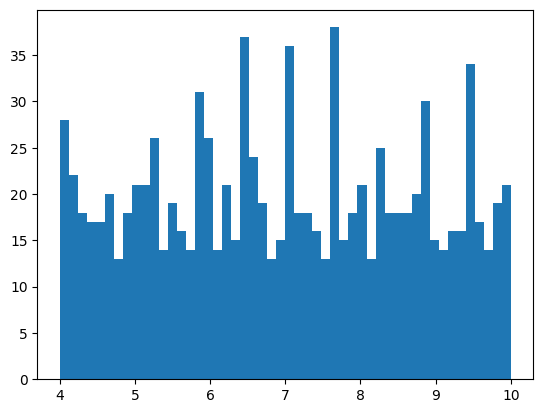

In [10]:
plt.hist(regression_dataset['Rating'], 50)
plt.show()

Come puoi vedere, la distribuzione dei rating è più o meno uniforme e non c'è skewness.

Il discorso è invece diverso per l'utile lordo:

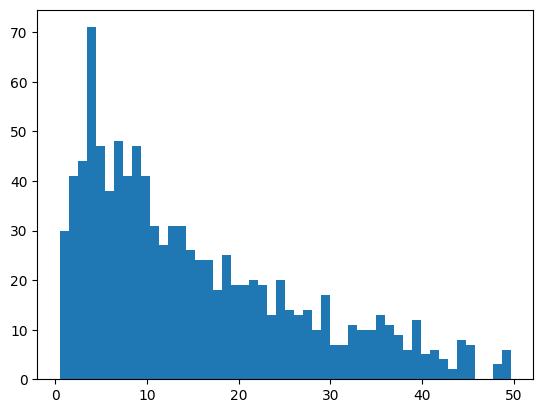

In [11]:
plt.hist(regression_dataset['gross income'], 50)
plt.show()

Come puoi vedere, qui la skewness c'è eccome e la maggioranza degli ordini sembra avere un income lordo basso.
Qual è, quindi, il valore di questa skewness esattamente? Tocca a te scoprirlo nella prossima cella!

Un piccolo consiglio: farlo con Numpy non è il modo più semplice!

In [12]:
# Codice per calcolare la skewness del gross income
from scipy.stats import skew
skew_rating = skew(regression_dataset["gross income"], bias=False)   # stima campionaria non distorta (G₁)

# Se il dataset rappresenta tutta la popolazione e non un campione, si può utilizzare anche bias=True
# Ma raramente conviene...

print("Skewness:", skew_rating)


Skewness: 0.8925698049581422


# Encoding delle variabili categoriche

Come avrai sicuramente notato, ci sono delle variabili (come "Branch", "City", "Customer type", "Gender", "Product line" e "Payment") che non sono numeriche e che quindi non possono essere direttamente masticate dagli algoritmi che andrai a utilizzare più tardi.
Ricordi le **tecniche per effettuarne l'enconding**? Questo è il momento di usarle per trasformarle in vettori!

In [13]:
# codice per effettuare l'enconding delle variabili categoriche

# Ci sono due approcci:
# Nel primo potrei utilizzare pd.get_dummies
# Nel secondo posso utilizzare il One Hot Encoder di sklearn.
# Uso la seconda perché più funzionale per un creare un workflow di modellazione
# P.s. Potrei anche incapsulare mediante Pipeline, inserendo Imputer e OneHotEnc
# per renderlo effettivamente un modello da produzione.

from sklearn.preprocessing import OneHotEncoder

y = regression_dataset["Rating"]                 # la variabile target
X = regression_dataset.drop(columns=["Rating"])  # tutte le feature meno la var target

cat_cols = ["Branch", "City", "Customer type", "Gender",
            "Product line", "Payment"] # Colonne categoriche da trasformare
num_cols = X.columns.difference(cat_cols)   # tutto il resto

ohe = OneHotEncoder(
    handle_unknown="ignore",   # niente errori se arriva una categoria nuova
    sparse_output=False,       # array denso → DataFrame più facile
    dtype="int8"               # riduce l’uso di memoria
)

ohe.fit(X[cat_cols])

# Trasformo le colonne categoriche
cat_encoded = ohe.transform(X[cat_cols])        # NumPy array

# Converto in Dataframe
cat_enc_df = pd.DataFrame(
    cat_encoded,
    columns=ohe.get_feature_names_out(cat_cols),
    index=X.index            # preserva l’allineamento delle righe
)

# Ricompongo il dataset completo
X_encoded = pd.concat(
    [X[num_cols].reset_index(drop=True),   # feature numeriche originali
     cat_enc_df.reset_index(drop=True)],   # dummies
    axis=1
)

print(f"Shape post OneHotEncoding: {X_encoded.shape}")


Shape post OneHotEncoding: (1000, 22)


In [14]:
#pandas options
pd.options.display.max_rows = 30
pd.options.display.max_columns = 30

X_encoded.head()

,Quantity,Unit price,gross income,Branch_A,Branch_B,Branch_C,City_Mandalay,City_Naypyitaw,City_Yangon,Customer type_Member,Customer type_Normal,Gender_Female,Gender_Male,Product line_Electronic accessories,Product line_Fashion accessories,Product line_Food and beverages,Product line_Health and beauty,Product line_Home and lifestyle,Product line_Sports and travel,Payment_Cash,Payment_Credit card,Payment_Ewallet
0,7,74.69,26.1415,1,0,0,0,0,1,1,0,1,0,0,0,0,1,0,0,0,0,1
1,5,15.28,3.8200,0,0,1,0,1,0,0,1,1,0,1,0,0,0,0,0,1,0,0
2,7,46.33,16.2155,1,0,0,0,0,1,0,1,0,1,0,0,0,0,1,0,0,1,0
3,8,58.22,23.2880,1,0,0,0,0,1,1,0,0,1,0,0,0,1,0,0,0,0,1
4,7,86.31,30.2085,1,0,0,0,0,1,0,1,0,1,0,0,0,0,0,1,0,0,1


# Feature Scaling

Nel dataset ci sono alcune feature che potrebbero essere standardizzate/normalizzate: quelle più evidenti sono sicuramente il prezzo del singolo oggetto, ovvero "Unit price", e "gross income" che come hai visto ha una grossa skewness. Questo dovrebbe migliorare la performance dei modelli che andrai a costruire a brevissimo, per cui ti chiedo di procedere in tal senso con la **standardizzazione**:

In [15]:
# codice per effettuare la standardizzazione della colonna "Unit price" e "gross income"

from sklearn.preprocessing import StandardScaler

cols_to_scale = ["Unit price", "gross income"]

scaler = StandardScaler()
X_scaled_values = scaler.fit_transform(X_encoded[cols_to_scale])

# convertiamo in DataFrame per facilità di concat
X_scaled_df = pd.DataFrame(
    X_scaled_values,
    columns=[f"{c}_std" for c in cols_to_scale],
    index=X_encoded.index
)

# Droppo le colonne originali e rimpiazzo con le feature scalate
X_encoded = X_encoded.drop(columns=cols_to_scale).join(X_scaled_df)

In [16]:
# Se tutto è andato bene, dovrei ottenere std ≈ 1 e mean ≈ 0

print(X_scaled_df.describe().loc[["mean", "std"]])

# Si, direi che va bene.

      Unit price_std  gross income_std
mean   -1.065814e-16      1.243450e-16
std     1.000500e+00      1.000500e+00


In [17]:
X_encoded.head()

,Quantity,Branch_A,Branch_B,Branch_C,City_Mandalay,City_Naypyitaw,City_Yangon,Customer type_Member,Customer type_Normal,Gender_Female,Gender_Male,Product line_Electronic accessories,Product line_Fashion accessories,Product line_Food and beverages,Product line_Health and beauty,Product line_Home and lifestyle,Product line_Sports and travel,Payment_Cash,Payment_Credit card,Payment_Ewallet,Unit price_std,gross income_std
0,7,1,0,0,0,0,1,1,0,1,0,0,0,0,1,0,0,0,0,1,0.718160,0.919607
1,5,0,0,1,0,1,0,0,1,1,0,1,0,0,0,0,0,1,0,0,-1.525303,-0.987730
2,7,1,0,0,0,0,1,0,1,0,1,0,0,0,0,1,0,0,1,0,-0.352781,0.071446
3,8,1,0,0,0,0,1,1,0,0,1,0,0,0,1,0,0,0,0,1,0.096214,0.675780
4,7,1,0,0,0,0,1,0,1,0,1,0,0,0,0,0,1,0,0,1,1.156959,1.267125


# Train e Test Split

Bene, è quindi giunta l'ora di affrontare l'ultima fase prima di allenare un modello di machine learning: l**o split fra training e test set**!
Per un primo approccio ti suggeriamo di usare una ratio 80:20 o 70:30, che il più delle volte funzionano bene.

Ti chiediamo di chiamare le feature di train, le feature di test, la label di train e le label di test rispettivamente con i nomi *X_train*, *X_test*, *y_train* e *y_test*:

In [18]:
from sklearn.model_selection import train_test_split

# codice per splittare il dataset in training set e test set

# X_encoded  → matrice finale delle feature  (dopo encoding + scaling)
# y          → label (colonna Rating)

# Imposto un seed per la riproducibilità

SEED = 42 # è la risposta alla domanda fondamentale sulla vita, l'universo e tutto quanto

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,          # feature matrix
    y,                  # target vector
    test_size=0.20,     # 0.20 ⇒ 80 % train / 20 % test
    random_state=SEED,  # riproducibilità degli esperimenti
    shuffle=True        # rimescola le righe prima di splittare
)

print(f"Train shape → X:{X_train.shape}, y:{y_train.shape}")
print(f"Test  shape → X:{X_test.shape}, y:{y_test.shape}")

Train shape → X:(800, 22), y:(800,)
Test  shape → X:(200, 22), y:(200,)


# Linear Regression

Ora è giunto il momento di predire i **Rating** usando il modello più semplice che hai visto, ovvero la linear regression!
Ti chiediamo di chiamare il modello *regressor*.

Procedi pure nella cella che segue:

In [19]:
# training del modello con la linear regression

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Istanzia il modello e usa tutti i core disponibili
regressor: LinearRegression = LinearRegression(n_jobs=-1)

# Fit sul training set
regressor.fit(X_train, y_train)

# Predizioni sul test set
y_pred = regressor.predict(X_test)

# Metriche di base
MSE = mean_squared_error(y_test, y_pred)
MAE = mean_absolute_error(y_test, y_pred)
R2 = r2_score(y_test, y_pred) # Coefficiente di determinazione - quota di varianza

Adesso che il training è avvenuto è il momento di valutare come questo performa. Le metriche che prendiamo in considerazione, che sono le principali per la regressione lineare, sono **il mean squadred error e il mean absolute error**. Ti chiediamo di calcolarle (sempre usando sklearn), avendo cura di chiamarle rispettivamente *MSE* e *MAE*. Punta a renderle il più vicine allo zero possibile, perché il modello è più di qualità quanto più queste sono zero:

In [20]:
print('MSE =', MSE, '\nMAE =', MAE)
print(f"R²  = {R2:.4f}")

MSE = 3.110187291026072 
MAE = 1.5229214208487527
R²  = -0.0138


In [21]:
# Posso concludere che il modello non performa abbastanza bene, in quanto sbaglia (in media) di 1.5 punti sul rating.
# Secondo me OneHot, avendo generato 19 colonne binarie su un dataset di 1000 record, ha reso i coefficienti instabili.
# Potrebbe esserci overfitting nel test set?

# Polynomial Regression

Prova in questa sezione a lavorare in modo simile a quanto fatto per la linear regression, ma usando la polynomial regression, che è sicuramente più potente della prima.

Come prima, ti chiediamo di chiamare *regressor* il modello e *poly_regressor* l'oggetto relativo alle feature polinomiali:

In [22]:
# training del modello con la polynomial regression

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Seleziona le due numeriche (già standardizzate) da espandere
num_cols_poly = ["Unit price_std", "gross income_std"]

# Costruisce e *fitta* il generatore di feature polinomiali (grado 2)
poly_regressor = PolynomialFeatures(
    degree=2,
    include_bias=False      # niente colonna di 1: la intercetta è già nel modello
)
X_train_poly = poly_regressor.fit_transform(X_train[num_cols_poly])
X_test_poly  = poly_regressor.transform(X_test[num_cols_poly]) # solo transform sul test

# Concatena le nuove colonne polinomiali alle altre feature
poly_names = poly_regressor.get_feature_names_out(num_cols_poly)

X_train_poly_df = pd.DataFrame(X_train_poly, columns=poly_names, index=X_train.index)
X_test_poly_df  = pd.DataFrame(X_test_poly,  columns=poly_names, index=X_test.index)

# Rimuovi le due colonne originali standardizzate per evitare duplicati
other_cols = X_train.columns.difference(num_cols_poly)

X_train_final = pd.concat([X_train[other_cols].reset_index(drop=True),
                           X_train_poly_df.reset_index(drop=True)], axis=1)
X_test_final  = pd.concat([X_test[other_cols].reset_index(drop=True),
                           X_test_poly_df.reset_index(drop=True)],  axis=1)

# Istanzia e *fitta* il regressore lineare sui dati estesi
regressor = LinearRegression(n_jobs=-1)
regressor.fit(X_train_final, y_train)

# Predizioni e metriche di valutazione
y_pred = regressor.predict(X_test_final)

# Metriche di base
MSE = mean_squared_error(y_test, y_pred)
MAE = mean_absolute_error(y_test, y_pred)
R2 = r2_score(y_test, y_pred) # Coefficiente di determinazione - quota di varianza

Come cambiano le performance? C'è effettivamente un miglioramento nell'MSE e nell'MAE?

In [23]:
print('MSE =', MSE, '\nMAE =', MAE)
print(f"R²  = {R2:.4f}")

MSE = 3.1792709562346806 
MAE = 1.5329586683117842
R²  = -0.0363


# Logistic Regression

In questa sezione si cambia dataset, in quanto cambia la natura del problema: si passa infatti a un problema di classificazione, in cui andrai a valutare la qualità di alcune mele destinate alla catena di supermercati per decidere quali sono le mele di qualità migliore.

La prima cosa è da fare è** importare il nuovo dataset**, ovvero apple_quality, che questa volta ti chiediamo di fare in autonomia, chiamando il dataset *classification_dataset*:

In [24]:
# codice per importare il dataset apple_quality

from google.colab import drive
drive.mount('/content/drive')

classification_raw_dataset = pd.read_csv('/content/drive/MyDrive/dataset/adv_analytics/apple_quality.csv', encoding='windows-1254')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Ti suggeriamo quindi  di printare le prime 50 righe...

In [25]:
# codice per print delle prime 50 righe

classification_raw_dataset.head(50)

,A_id,Size,Weight,Sweetness,Crunchiness,Juiciness,Ripeness,Acidity,Quality
0,0.0,-3.970049,-2.512336,5.346330,-1.012009,1.844900,0.329840,-0.491590483,good
1,1.0,-1.195217,-2.839257,3.664059,1.588232,0.853286,0.867530,-0.722809367,good
2,2.0,-0.292024,-1.351282,-1.738429,-0.342616,2.838636,-0.038033,2.621636473,bad
3,3.0,-0.657196,-2.271627,1.324874,-0.097875,3.637970,-3.413761,0.790723217,good
4,4.0,1.364217,-1.296612,-0.384658,-0.553006,3.030874,-1.303849,0.501984036,good
...,...,...,...,...,...,...,...,...,...
45,45.0,0.033471,-0.044161,-0.481202,4.937210,-0.609873,-3.231504,1.248791791,good
46,46.0,-0.487367,-0.768805,-0.779232,2.025257,1.477927,0.267788,-4.454570173,good
47,47.0,-1.387990,2.738511,-2.349217,0.953438,1.860716,2.317310,3.097818375,bad
48,48.0,-3.328571,0.652577,-1.424403,0.727385,1.576921,2.577804,0.650677868,bad


... e dei metadati delle colonne:

In [26]:
# codice per visualizzare i principali metadata del dataset apple_quality

classification_raw_dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4001 entries, 0 to 4000
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   A_id         4000 non-null   float64
 1   Size         4000 non-null   float64
 2   Weight       4000 non-null   float64
 3   Sweetness    4000 non-null   float64
 4   Crunchiness  4000 non-null   float64
 5   Juiciness    4000 non-null   float64
 6   Ripeness     4000 non-null   float64
 7   Acidity      4001 non-null   object 
 8   Quality      4000 non-null   object 
dtypes: float64(7), object(2)
memory usage: 281.4+ KB


In [129]:
classification_raw_dataset.describe()

,A_id,Size,Weight,Sweetness,Crunchiness,Juiciness,Ripeness
count,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000
mean,1999.500000,-0.503015,-0.989547,-0.470479,0.985478,0.512118,0.498277
std,1154.844867,1.928059,1.602507,1.943441,1.402757,1.930286,1.874427
min,0.000000,-7.151703,-7.149848,-6.894485,-6.055058,-5.961897,-5.864599
25%,999.750000,-1.816765,-2.011770,-1.738425,0.062764,-0.801286,-0.771677
50%,1999.500000,-0.513703,-0.984736,-0.504758,0.998249,0.534219,0.503445
75%,2999.250000,0.805526,0.030976,0.801922,1.894234,1.835976,1.766212
max,3999.000000,6.406367,5.790714,6.374916,7.619852,7.364403,7.237837


In [27]:
# Ho verificato, e si, ci sono dati mancanti
nan_counts = classification_raw_dataset.isnull().sum()
print(nan_counts)

A_id           1
Size           1
Weight         1
Sweetness      1
Crunchiness    1
Juiciness      1
Ripeness       1
Acidity        0
Quality        1
dtype: int64


In [28]:
# L'errore è dato dall'ultima colonna del dataset, dove c'è la firma del creatore.
# Rimuovo quindi l'ultima riga
classification_dataset = classification_raw_dataset.dropna()
classification_dataset = classification_dataset.drop(columns="A_id") #non serve nell'addestramento

In [29]:
classification_dataset.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Size         4000 non-null   float64
 1   Weight       4000 non-null   float64
 2   Sweetness    4000 non-null   float64
 3   Crunchiness  4000 non-null   float64
 4   Juiciness    4000 non-null   float64
 5   Ripeness     4000 non-null   float64
 6   Acidity      4000 non-null   object 
 7   Quality      4000 non-null   object 
dtypes: float64(6), object(2)
memory usage: 281.2+ KB


Come puoi vedere, il dataset è già pulito e quasi tutte le colonne sono numeriche. L'unica a non esserlo è proprio la label, che va encodata:

In [30]:
# codice per effettuare l'enconding della label "Quality"

# Istanza dell'encoder
encoder: OneHotEncoder = OneHotEncoder(
    drop="first",           # drop='first' evita la multicollinearità (dummy-variable trap)
    sparse_output=False,
    dtype=int,              # così ottengo 0/1 interi
    handle_unknown="error"  # alza un errore se appare una nuova categoria
    )

# Fit & transform colonna ‘Quality’
quality_encoded = ohe.fit_transform(classification_dataset[['Quality']])
encoded_cols = ohe.get_feature_names_out(['Quality'])

# Concateno le colonne post encoding con le altre numeriche

df_encoded_quality = pd.DataFrame(quality_encoded, columns=encoded_cols, index=classification_dataset.index)
df_final = pd.concat([classification_dataset.drop(columns=['Quality']), df_encoded_quality], axis=1)

#
print("Encoded columns:", list(encoded_cols))
print("Final DataFrame shape:", df_final.shape)

Encoded columns: ['Quality_bad', 'Quality_good']
Final DataFrame shape: (4000, 9)


In [31]:
df_final.head()

,Size,Weight,Sweetness,Crunchiness,Juiciness,Ripeness,Acidity,Quality_bad,Quality_good
0,-3.970049,-2.512336,5.346330,-1.012009,1.844900,0.329840,-0.491590483,0,1
1,-1.195217,-2.839257,3.664059,1.588232,0.853286,0.867530,-0.722809367,0,1
2,-0.292024,-1.351282,-1.738429,-0.342616,2.838636,-0.038033,2.621636473,1,0
3,-0.657196,-2.271627,1.324874,-0.097875,3.637970,-3.413761,0.790723217,0,1
4,1.364217,-1.296612,-0.384658,-0.553006,3.030874,-1.303849,0.501984036,0,1


['Size', 'Weight', 'Sweetness', 'Crunchiness', 'Juiciness', 'Ripeness', 'Acidity']


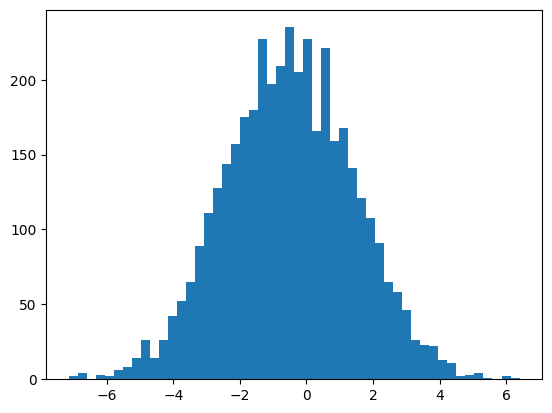

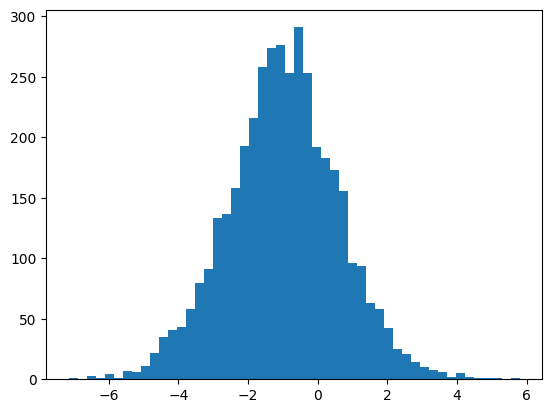

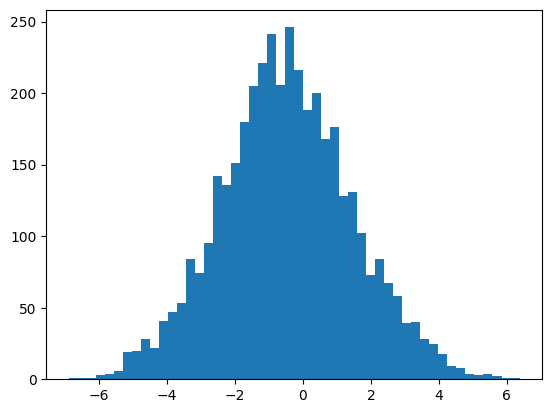

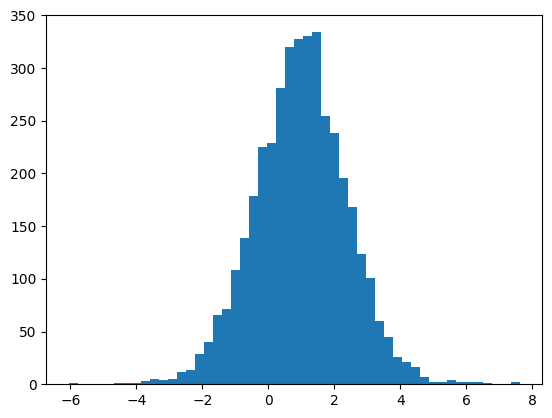

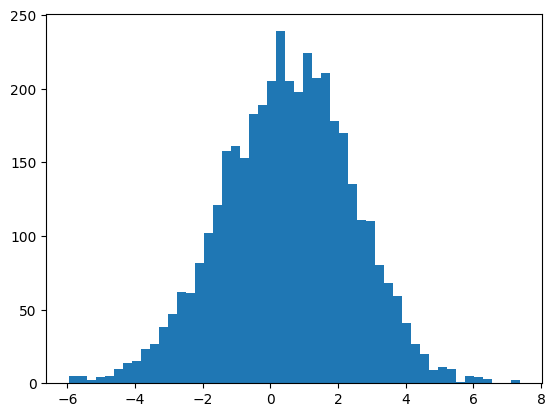

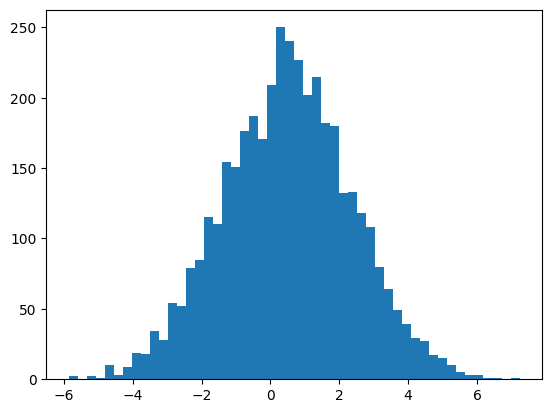

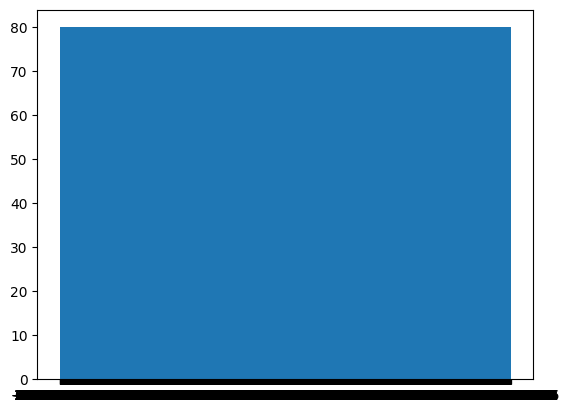

In [32]:
# Verifico se tutte le distribuzioni sono simmetriche

columns = ['Size', 'Weight', 'Sweetness', 'Crunchiness', 'Juiciness', 'Ripeness',
           'Acidity']

print(columns)

for c in columns:
  plt.hist(df_final[c], 50)
  plt.show()

Bisogna poi ri-effettuare la divisione fra porzione di addestramento e porzione di test, usando la nomenclatura vista in precedenza:

In [33]:
# codice per splittare in train/test il dataset apple_quality

from sklearn.model_selection import train_test_split

# Separo features (X) e labels (y)
label_cols = ['Quality_bad', 'Quality_good']
X = df_final.drop(columns=label_cols)
y = df_final[label_cols]

# Train‑test split (20 % test set)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=SEED,
    stratify=y, # preserva la distribuzione delle classi
)

print("Shapes:")
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

# Faccio un check delle classi per vedere se sono bilanciate
def class_dist(df):
    return {
        'bad': int(df['Quality_bad'].sum()),
        'good': int(df['Quality_good'].sum()),
    }

print("\nClass distribution:")
print("Full  :", class_dist(y))
print("Train :", class_dist(y_train))
print("Test  :", class_dist(y_test))

Shapes:
X_train: (3200, 7)
X_test : (800, 7)
y_train: (3200, 2)
y_test : (800, 2)

Class distribution:
Full  : {'bad': 1996, 'good': 2004}
Train : {'bad': 1597, 'good': 1603}
Test  : {'bad': 399, 'good': 401}


In [34]:
# Bene, le classi sono abbastanza bilanciate.

Puoi finalmente usare la logistic regression per allenare il modello vero e proprio, che ti chiedo di chiamare *logistic_regressor*:

In [35]:
# codice per trainare il modello usando la logistic regression

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Metto un solo target binario. (Quality_good: 1 = good apple, 0 = bad apple)
y_train_bin = y_train["Quality_good"]
y_test_bin = y_test["Quality_good"]

# Feature scaling
#scaler = StandardScaler()
#X_train_scaled = scaler.fit_transform(X_train)
#X_test_scaled = scaler.transform(X_test)

# Train della regressione logistica
logistic_regressor = LogisticRegression(
    random_state=SEED,
    max_iter=1000,
    solver="lbfgs",
)
logistic_regressor.fit(X_train, y_train_bin)

LogisticRegression(max_iter=1000, random_state=42)

Una metrica che ti permette subito di valutare la bontà del modello, come saprai, è l'***F1 score***, che dovrebbe essere idealmente superiore a 0.80. Cerca anche di massimizzare la media della precision e del recall, che idealmente dovrebbero anch'essi essere superiori a 0.80:

In [36]:
from sklearn.metrics import classification_report

y_predict_test = logistic_regressor.predict(X_test)

print(classification_report(y_test_bin, y_predict_test))

              precision    recall  f1-score   support

           0       0.78      0.70      0.74       399
           1       0.73      0.81      0.77       401

    accuracy                           0.75       800
   macro avg       0.76      0.75      0.75       800
weighted avg       0.76      0.75      0.75       800



Ora è intessante andare a "disegnare" la **confusion matrix**, che ti mostra quali sono le categorie su cui il modello che hai costruito è "bravo" e su quali no, così da eventualmente avere delle informazioni in più per migliorarlo. Prova a farlo in autonomia usando scikit-learn:

In [37]:
# codice per la confusion matrix

conf_matrix = confusion_matrix(y_test_bin, y_predict_test)
conf_df = pd.DataFrame(
    conf_matrix,
    index=["Actual bad", "Actual good"],
    columns=["Pred bad", "Pred good"],
)

# 5. Feature importance (coefficients)
coef_df = (
    pd.DataFrame(
        {
            "Feature": X_train.columns,
            "Coefficient": logistic_regressor.coef_[0],
        }
    )
    .sort_values("Coefficient", ascending=False)
    .reset_index(drop=True)
)


print(conf_df)
print()
print(coef_df)

             Pred bad  Pred good
Actual bad        280        119
Actual good        78        323

       Feature  Coefficient
0         Size     0.656441
1    Sweetness     0.580408
2    Juiciness     0.414661
3       Weight     0.269258
4  Crunchiness     0.019274
5     Ripeness    -0.130096
6      Acidity    -0.293151


# Decision Tree

**Puoi provare a usare un decision tree per capire se può migliorare le prestazioni del modello basato su logistic regression.** Generalmente, come visto durante la parte teorica del Corso, i decision tree sono più potenti, ma scoprilo costruendone uno!

Il procedimento non è dissimile da quelli usati in precedenza, quindi procedi pure al training:

In [42]:
# training del modello con un decision tree

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


# Baseline Decision Tree (no scaling needed)
dt_classifier = DecisionTreeClassifier(
    random_state=SEED,
    max_depth=None,        # let the tree grow fully (can prune later)
    min_samples_split=2,
    min_samples_leaf=1,
)

dt_classifier.fit(X_train, y_train["Quality_good"])

# Predictions & metrics
y_pred_dt = dt_classifier.predict(X_test)
accuracy_dt = accuracy_score(y_test["Quality_good"], y_pred_dt)


class_report_dt = classification_report(
    y_test["Quality_good"],
    y_pred_dt,
    target_names=["bad", "good"],
    digits=3,
)

print("\nClassification report:\n", class_report_dt)


Classification report:
               precision    recall  f1-score   support

         bad      0.800     0.802     0.801       399
        good      0.802     0.800     0.801       401

    accuracy                          0.801       800
   macro avg      0.801     0.801     0.801       800
weighted avg      0.801     0.801     0.801       800



E poi alla costruzione della confusion matrix:

In [43]:
# confusion matrix del decision tree

# Confusion matrix
conf_matrix_dt = confusion_matrix(y_test["Quality_good"], y_pred_dt)
conf_df_dt = pd.DataFrame(
    conf_matrix_dt,
    index=["Actual bad", "Actual good"],
    columns=["Pred bad", "Pred good"],
)

print(conf_df_dt)

             Pred bad  Pred good
Actual bad        320         79
Actual good        80        321


Quanti sono gli errori? Di più o di meno di quelli commessi dal modello con la logistic regression?

Quali sono le feature che sono state più importanti per il decision tree che hai costruito? Scoprilo con la feature importance, che ti invitiamo a calcolare e poi a printare nella cella che segue:

In [46]:
# codice per la feature importance

# Feature importance
feat_imp_dt = (
    pd.DataFrame(
        {
            "Feature": X_train.columns,
            "Importance": dt_classifier.feature_importances_,
        }
    )
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

print(feat_imp_dt.head(10))

       Feature  Importance
0    Sweetness    0.190589
1         Size    0.181638
2    Juiciness    0.154056
3     Ripeness    0.132387
4      Acidity    0.124169
5       Weight    0.109103
6  Crunchiness    0.108059


# K-Means Clustering

Eccoci al K-Means Clustering, il più utilizzato algoritimo tra quelli non supervisionati.

Per prima cosa bisogna eliminare la label perché, come sai, il K-Means Clustering è un algoritmo non supervisionato e non deve quindi averla:

In [65]:
# Salvo le etichette vere SOLO per valutazione a posteriori
y_true = classification_dataset['Quality'] # utilizzerò y_true per il test successivo

clustering_dataset = classification_dataset.drop(columns=['Quality'])

In [66]:
y_true

,Quality
0,good
1,good
2,bad
3,good
4,good
...,...
3995,bad
3996,good
3997,bad
3998,good


In [67]:
clustering_dataset

,Size,Weight,Sweetness,Crunchiness,Juiciness,Ripeness,Acidity
0,-3.970049,-2.512336,5.346330,-1.012009,1.844900,0.329840,-0.491590483
1,-1.195217,-2.839257,3.664059,1.588232,0.853286,0.867530,-0.722809367
2,-0.292024,-1.351282,-1.738429,-0.342616,2.838636,-0.038033,2.621636473
3,-0.657196,-2.271627,1.324874,-0.097875,3.637970,-3.413761,0.790723217
4,1.364217,-1.296612,-0.384658,-0.553006,3.030874,-1.303849,0.501984036
...,...,...,...,...,...,...,...
3995,0.059386,-1.067408,-3.714549,0.473052,1.697986,2.244055,0.137784369
3996,-0.293118,1.949253,-0.204020,-0.640196,0.024523,-1.087900,1.854235285
3997,-2.634515,-2.138247,-2.440461,0.657223,2.199709,4.763859,-1.334611391
3998,-4.008004,-1.779337,2.366397,-0.200329,2.161435,0.214488,-2.229719806


Prova a trainare il modello usando l'algoritmo in oggetto, il procedimento è sempre simile a quanto visto in precedenza. Prova a settare dapprima il numero dei cluster a due (in quanto sappiamo che il dataset contiene mele buone o non buone):

In [74]:
# codice per trainare il modello con K-Means Clustering
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Preparo il dataset

# Dataset di clustering (niente label)
X = clustering_dataset
# utilizzerò y_true per il test successivo


# Standardizzazione (il K-Means è sensibile alla scala)
scaler = StandardScaler().fit(X)
X_scaled = scaler.transform(X)

# Modello K-Means con 2 cluster
kmeans = KMeans(
    n_clusters=2,        # sappiamo che i gruppi teorici sono 2
    n_init=10,           # 10 ri-inizializzazioni
    random_state=SEED
)
clusters = kmeans.fit_predict(X_scaled)

# Associazione cluster → qualità predominante
mapping = {}
for cluster in range(2):
    indices = (clusters == cluster)
    majority_quality = y_true[indices].mode()[0]
    mapping[cluster] = majority_quality

# Distribuzione delle qualità in ogni cluster
cluster_summary = (
    pd.concat([pd.Series(clusters, name="Cluster"), y_true], axis=1)
      .groupby(["Cluster", "Quality"])
      .size()
      .unstack(fill_value=0)
)
# Dimensione totale
cluster_summary["Total"] = cluster_summary.sum(axis=1)

# Valutazione empirica dell'accuracy del mapping
pred_quality = pd.Series(clusters).map(mapping)
accuracy = (pred_quality == y_true).mean()



print("=== Risultati modello K-Means (k=2) ===")
print(f"Mapping cluster -> qualità: {mapping}")
print(f"Accuratezza empirica: {accuracy:.2%}\n")
print("Distribuzione qualità per cluster:")
print(cluster_summary, "\n")

=== Risultati modello K-Means (k=2) ===
Mapping cluster -> qualità: {0: 'bad', 1: 'good'}
Accuratezza empirica: 63.08%

Distribuzione qualità per cluster:
Quality   bad  good  Total
Cluster                   
0        1292   773   2065
1         704  1231   1935 



Effettua quindi una predizione e vedi a che qualità corrisponde la mela che hai dato in input al modello:

In [75]:
# codice per effettuare la predizione su una mela dalle caratteristiche a piacere

# Esempio di predizione della prima riga del dataset
sample_features = X.iloc[[0]]
sample_scaled = scaler.transform(sample_features)
sample_cluster = kmeans.predict(sample_scaled)[0]
sample_quality = mapping[sample_cluster]

print("Esempio di mela in input (prima riga del dataset):")
print(sample_features)
print(f"\nCluster assegnato: {sample_cluster} --> Qualità stimata: {sample_quality}")

Esempio di mela in input (prima riga del dataset):
       Size    Weight  Sweetness  Crunchiness  Juiciness  Ripeness  \
0 -3.970049 -2.512336    5.34633    -1.012009     1.8449   0.32984   

        Acidity  
0  -0.491590483  

Cluster assegnato: 1 --> Qualità stimata: good


In [76]:
# La predizione è andata bene!

A che cluster è stata assegnata la mela, è buona o cattiva?
Che succede se invece provi a settare il numero di cluster a tre? Testa questo scenario e rifai la predizione, magari potresti scoprire che in realtà ci sono anche delle mele di qualità intermedia!

In [77]:
# KMeans with k=3
kmeans3 = KMeans(n_clusters=3, random_state=SEED, n_init=10)
cluster_labels3 = kmeans3.fit_predict(X_scaled)

# Associazione cluster → qualità predominante
mapping3 = {}
for cl in range(3):
    qual_mode = y_true[cluster_labels3 == cl].mode()[0]
    mapping3[cl] = qual_mode

# Valutazione empirica dell'accuracy del mapping
pred_quality3 = pd.Series(cluster_labels3).map(mapping3)
accuracy3 = (pred_quality3 == y_true).mean()

# Distribuzione delle qualità in ogni cluster
cluster_summary = (
    pd.concat([pd.Series(cluster_labels3, name="Cluster"), y_true], axis=1)
      .groupby(["Cluster", "Quality"])
      .size()
      .unstack(fill_value=0)
)
# Dimensione totale
cluster_summary["Total"] = cluster_summary.sum(axis=1)

# Esempio di predizione della prima riga del dataset
sample = X.iloc[[0]]
sample_scaled = scaler.transform(sample)
sample_cluster3 = kmeans3.predict(sample_scaled)[0]
sample_quality3 = mapping3[sample_cluster3]

# Stampa dei risultati
print("=== K-Means con k = 3 ===")
print(f"Mapping cluster → qualità: {mapping3}")
print(f"Accuratezza empirica: {accuracy3:.2%}\n")
print("Distribuzione qualità per cluster:")
print(cluster_summary, "\n")
print("Esempio di mela (prima riga del dataset):")
print(sample)
print(f"\nCluster assegnato: {sample_cluster3} --> Qualità stimata: {sample_quality3}")

=== K-Means con k = 3 ===
Mapping cluster → qualità: {0: 'good', 1: 'good', 2: 'bad'}
Accuratezza empirica: 56.97%

Distribuzione qualità per cluster:
Quality  bad  good  Total
Cluster                  
0        708   765   1473
1        385   611    996
2        903   628   1531 

Esempio di mela (prima riga del dataset):
       Size    Weight  Sweetness  Crunchiness  Juiciness  Ripeness  \
0 -3.970049 -2.512336    5.34633    -1.012009     1.8449   0.32984   

        Acidity  
0  -0.491590483  

Cluster assegnato: 0 --> Qualità stimata: good


# Conclusioni
## Mela di esempio

Con k = 2 era finita nel cluster 1 (qualità good).

Con k = 3 ora ricade nel cluster 0, che mappiamo ancora a good (modalità dominante).

L'accuratezza crolla dal 63% al 57% circa. Questo perchè con 3 centroidi ho diviso ulteriormente lo spazio e i due cluster associati a "good" si contendono gli stessi punti. C'è il rischio che gli outlier possano finire nel cluster sbagliato.

# Time Series

L'ultimo tema del progetto è quello delle time series: se ci hai fatto caso, il dataset che hai utilizzato per la regressione è in realtà una time series a cui, per il problema di regressione stesso, è stata eliminata l'informazione sul tempo in quanto non utile in quello use case. Adesso è tempo di riprenderla!
In questo scenario vogliamo provare a **capire come i gross income evolvono nel tempo**, quindi prendi il dataset originale, ovvero *regression_raw_dataset* ed elimina tutte le colonne, tenendo solo "Date" e "gross income" e avendo cura di chiamare *timeseries_dataset* il nuovo dataset:

In [79]:
# codice per costruire un nuovo dataset, partendo da regression_raw_dataset, con solo le colonne "Date" e "gross income"

timeseries_dataset = regression_raw_dataset[["Date", "gross income"]].copy()

Dai un rapido sguardo al nuovo dataset creato, per assicurarti che sia tutto ok:

In [80]:
timeseries_dataset.head(100)

,Date,gross income
0,1/5/2019,26.1415
1,3/8/2019,3.8200
2,3/3/2019,16.2155
3,1/27/2019,23.2880
4,2/8/2019,30.2085
...,...,...
95,3/8/2019,4.8580
96,3/29/2019,43.9350
97,2/9/2019,3.7350
98,3/23/2019,7.9125


A questo punto prova a utilizzare la **linear regression** su questa serie temporale, nello stesso modo di quanto già fatto in precedenza:

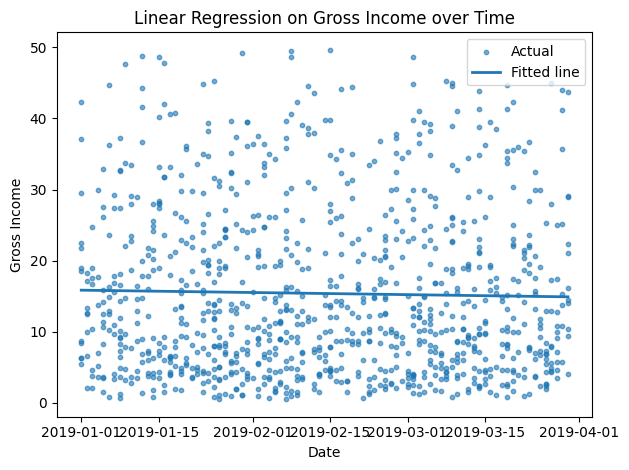

In [90]:
# training della time series con la linear regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Mi assicuro che il datetime dtype e l'ordine cronologico siano corretti
timeseries_dataset['Date'] = pd.to_datetime(timeseries_dataset['Date'])
timeseries_dataset = timeseries_dataset.sort_values('Date').reset_index(drop=True)

# Feature engineering: Giorni dalla prima osservazione
timeseries_dataset['days_since_start'] = (timeseries_dataset['Date'] - timeseries_dataset['Date'].min()).dt.days

# Preparo features e target
X = timeseries_dataset[['days_since_start']]
y = timeseries_dataset['gross income']

# Fitting del modello di Regressione Lineare
model = LinearRegression(n_jobs=-1)
model.fit(X, y)

# Predizioni
timeseries_dataset['predicted'] = model.predict(X)

# Valuto le performance del modello
MSE = mean_squared_error(y, timeseries_dataset['predicted'])
MAE = mean_absolute_error(y, timeseries_dataset['predicted'])

# Plot dei dati e della linea di fitting
plt.figure()
plt.scatter(timeseries_dataset['Date'], y, s=10, alpha=0.6, label='Actual')
plt.plot(timeseries_dataset['Date'], timeseries_dataset['predicted'], linewidth=2, label='Fitted line')
plt.xlabel('Date')
plt.ylabel('Gross Income')
plt.title('Linear Regression on Gross Income over Time')
plt.legend()
plt.tight_layout()

E vai a controllare le solite metriche, cioè MSE ed MAE:

In [91]:
print('MSE =', MSE, '\nMAE =', MAE)

MSE = 136.88768067988767 
MAE = 9.61585545546774


Ti renderai conto che probabilmente non sono così elevati come in precedenza, questo perché la regressione lineare sulle time series spesso fallisce e, come già visto nella teoria, c'è bisogno di altri modelli più perfomanti.

# Time Series con XGBoost (opzionale)

A proposito di modelli più performanti per le time series, ricordi XGBoost? Se ti va, puoi provare a impiegare quest'ultimo per costruire il modello. **Questa sezione è opzionale e non necessaria per superare il progetto.**

In [125]:
# (BONUS) training e performance evalutation della time series con XGBoost
from xgboost import XGBRegressor

# Feature engineering
timeseries_dataset['days_since_start'] = (timeseries_dataset['Date'] - timeseries_dataset['Date'].min()).dt.days
timeseries_dataset['day_of_week'] = timeseries_dataset['Date'].dt.weekday          # 0=Monday
timeseries_dataset['day_of_month'] = timeseries_dataset['Date'].dt.day
timeseries_dataset['month'] = timeseries_dataset['Date'].dt.month

# Le colonne di lag (lag 1, lag 7, …) servono a trasformare una serie temporale
# in un problema di apprendimento supervisionato “tabellare”,
# in modo che un algoritmo non-sequenziale come XGBoost possa «ricordare» il passato.
timeseries_dataset = timeseries_dataset.sort_values('Date').reset_index(drop=True)
timeseries_dataset['lag_1'] = timeseries_dataset['gross income'].shift(1)
timeseries_dataset['lag_7'] = timeseries_dataset['gross income'].shift(7)

# Rimuovo le righe con i NaNs generati dal lagging
timeseries_dataset = timeseries_dataset.dropna().reset_index(drop=True)

# Creo features and target
feature_cols = ['days_since_start', 'day_of_week', 'day_of_month', 'month', 'lag_1', 'lag_7']
X = timeseries_dataset[feature_cols]
y = timeseries_dataset['gross income']

# Train/test split mantenendo la cronologia (80% train, 20% test)
split_idx = int(len(timeseries_dataset) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

# Fit XGBoost regressor
model = XGBRegressor(
    n_estimators = 300,
    learning_rate = 0.05,
    max_depth = 4,
    subsample = 0.8,
    colsample_bytree = 0.8,
    objective = 'reg:squarederror',
    random_state = SEED
)
model.fit(X_train, y_train)

# Predizioni e valutazioni
y_pred = model.predict(X_test)
MSE = mean_squared_error(y_test, y_pred)
MAE = mean_absolute_error(y_test, y_pred)

# Preview predizioni
pred_df = pd.DataFrame({
    'Date': timeseries_dataset.loc[split_idx:, 'Date'].values,
    'Actual': y_test.values,
    'Predicted': y_pred
})

In [126]:
pred_df.head(10)

,Date,Actual,Predicted
0,2019-03-13,7.6600,7.343849
1,2019-03-13,13.5675,3.990553
2,2019-03-14,7.0940,17.384319
3,2019-03-14,19.1555,15.810612
4,2019-03-14,10.5660,12.150744
5,2019-03-14,34.8425,6.803422
6,2019-03-14,21.0330,11.973962
7,2019-03-14,41.2900,9.116696
8,2019-03-14,43.8660,18.252991
9,2019-03-14,9.7475,11.764065


In [127]:
print('MSE =', MSE, '\nMAE =', MAE)

MSE = 144.68841046869005 
MAE = 9.346909488947494


In [ ]:
# Non proprio bene...

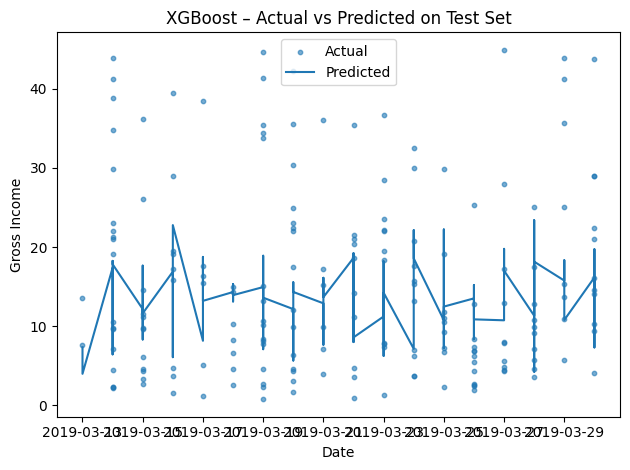

In [128]:
# Plot dei dati e della linea di fitting
plt.figure()
plt.scatter(pred_df['Date'], pred_df['Actual'], s=10, alpha=0.6,  label='Actual')
plt.plot(pred_df['Date'], pred_df['Predicted'], label='Predicted')
plt.xlabel('Date')
plt.ylabel('Gross Income')
plt.title('XGBoost – Actual vs Predicted on Test Set')
plt.legend()
plt.tight_layout()

# Conclusione

C'è ancora molto lavoro da fare... Anzitutto dovrei andare in maggiore profondità sull'analisi ed esplorazione dei dati, in quanto ho record distribuiti su 3 mesi in modo non uniforme.
Si potrebbe:
- aggiungere lag 2-, 3-, …, 14-giorni, rolling mean/median.
- fare onehotencoding giorno-della-settimana
- segnalare indicatori di città, festività.
- usare la GridSearchCV

E tanto altro ancora!

Visit my personal blog or let's connect on:

[Kaggle](https://https://www.kaggle.com/snocco)

[LinkedIn](https://https://www.linkedin.com/in/stefanonocco/)

[Instagram](https://https://www.instagram.com/steno.py/)

Stefano Nocco